# Optimus 5-Prime: Multiscale CNN

Predict MRL from 50 nt 5′UTR sequences. The main metric is squared Pearson correlation ($r^2$), with a target of 0.90.

Place `GSM3130435_egfp_unmod_1.csv.gz` beside this notebook, or change `DATA_FILE`. Requires PyTorch, NumPy, pandas and matplotlib.

Saved outputs are from the run before this cleanup. Training has not been rerun.


## Setup


In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

DATA_FILE = Path("GSM3130435_egfp_unmod_1.csv.gz")
OUTCOMES_DIR = Path("outcomes_multiscale")
OUTCOMES_DIR.mkdir(exist_ok=True)

seed = 42
batch_size = 256
learning_rate = 0.0003
weight_decay = 0.0001
num_epochs = 30
patience = 5
aux_weight = 0.1

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## Data

Sort by read count. Use the highest-read 20,000 sequences as the test set. Randomly split the next 260,000 into 240,000 training and 20,000 validation samples. Evaluate the remaining low-read sequences separately.


In [2]:
fraction_columns = [f"r{i}" for i in range(14)]
data = pd.read_csv(DATA_FILE, usecols=["utr", "rl", "total_reads"] + fraction_columns)
data = data.sort_values("total_reads", ascending=False, kind="stable").reset_index(drop=True)
low_read_data = data.iloc[280000:]
data = data.iloc[:280000]

rng = np.random.default_rng(seed)
indexes = rng.permutation(np.arange(20000, 280000))
training_indexes = indexes[:240000]
validating_indexes = indexes[240000:]
testing_indexes = np.arange(20000)

training = data.iloc[training_indexes]
validating = data.iloc[validating_indexes]
testing = data.iloc[testing_indexes]

# Save the split for later runs.
np.savez(OUTCOMES_DIR / "split_indexes.npz",
         training=training_indexes, validating=validating_indexes, testing=testing_indexes)
print("Training:", len(training))
print("Validation:", len(validating))
print("Final evaluation:", len(testing))
print("Low-read evaluation:", len(low_read_data))


Training: 240000
Validation: 20000
Final evaluation: 20000
Low-read evaluation: 46033


## Encoding

One-hot encode each sequence as `4 × 50`, using channel order `ATGC`. Standardize MRL with training-set statistics. The `r0`–`r13` columns are auxiliary labels; the model input is sequence only.


In [3]:
mrl_mean = float(training["rl"].mean())
mrl_std = float(training["rl"].std(ddof=0))

def one_hot_encode(utr):
    encoded = np.zeros((4, 50), dtype=np.float32)
    for i, nt in enumerate(utr):
        encoded["ATGC".index(nt), i] = 1
    return encoded

def make_dataset(frame):
    sequences = np.zeros((len(frame), 4, 50), dtype=np.float32)
    for i, utr in enumerate(frame["utr"]):
        sequences[i] = one_hot_encode(utr)
    mrls = (frame["rl"].to_numpy(dtype=np.float32) - mrl_mean) / mrl_std
    fractions = frame[fraction_columns].to_numpy(dtype=np.float32)
    return TensorDataset(torch.from_numpy(sequences), torch.from_numpy(mrls),
                         torch.from_numpy(fractions))

training_loader = DataLoader(make_dataset(training), batch_size=batch_size, shuffle=True)
validating_loader = DataLoader(make_dataset(validating), batch_size=batch_size)
testing_loader = DataLoader(make_dataset(testing), batch_size=batch_size)

print("Training MRL mean:", round(mrl_mean, 4))
print("Training MRL standard deviation:", round(mrl_std, 4))


Training MRL mean: 6.5341
Training MRL standard deviation: 1.5768


## Model

| Layer | Output shape |
| --- | --- |
| Sequence input | B × 4 × 50 |
| Parallel convolutions: kernels 3, 7, 11; 64 channels each | B × 192 × 50 |
| 1 × 1 convolution | B × 128 × 50 |
| Residual blocks: dilations 1, 2, 4 | B × 128 × 50 |
| Flatten → dense 128 → dense 32 | B × 32 |
| MRL head / fraction head | B / B × 14 |

B is batch size. Each residual block has two convolutions and a skip connection. The fraction head returns logits.


In [4]:
class ResidualBlock(nn.Module):
    def __init__(self, channels, dilation):
        super().__init__()
        padding = 2 * dilation
        self.conv1 = nn.Conv1d(channels, channels, kernel_size=5,
                               padding=padding, dilation=dilation)
        self.conv2 = nn.Conv1d(channels, channels, kernel_size=5,
                               padding=padding, dilation=dilation)
        self.bn1 = nn.BatchNorm1d(channels)
        self.bn2 = nn.BatchNorm1d(channels)
        self.gelu = nn.GELU()
        self.dropout = nn.Dropout(0.1)

    def forward(self, x):
        out = self.gelu(self.bn1(self.conv1(x)))
        out = self.dropout(self.bn2(self.conv2(out)))
        return self.gelu(out + x)


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv3 = nn.Conv1d(4, 64, kernel_size=3, padding=1)
        self.conv7 = nn.Conv1d(4, 64, kernel_size=7, padding=3)
        self.conv11 = nn.Conv1d(4, 64, kernel_size=11, padding=5)
        self.merge = nn.Conv1d(192, 128, kernel_size=1)
        self.bn = nn.BatchNorm1d(128)
        self.gelu = nn.GELU()
        self.block1 = ResidualBlock(128, dilation=1)
        self.block2 = ResidualBlock(128, dilation=2)
        self.block3 = ResidualBlock(128, dilation=4)
        self.fc1 = nn.Linear(6400, 128)
        self.fc2 = nn.Linear(128, 32)
        self.dropout = nn.Dropout(0.2)
        self.mrl_head = nn.Linear(32, 1)
        self.fraction_head = nn.Linear(32, 14)

    def forward(self, x):
        # Combine short and longer sequence patterns.
        short = self.gelu(self.conv3(x))
        medium = self.gelu(self.conv7(x))
        long = self.gelu(self.conv11(x))
        x = torch.cat((short, medium, long), dim=1)
        x = self.gelu(self.bn(self.merge(x)))
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(self.gelu(self.fc1(x)))
        x = self.gelu(self.fc2(x))
        return self.mrl_head(x).squeeze(1), self.fraction_head(x)


## Training functions

Loss = MSE on standardized MRL + 0.1 × KL divergence on fraction distributions. Compute Pearson $r^2$ across the full dataset. Report MSE in original MRL units.


In [5]:
mse_loss = nn.MSELoss()
kl_loss = nn.KLDivLoss(reduction="batchmean")

def calculate_metrics(actual, predicted):
    actual = actual.astype(np.float64)
    predicted = predicted.astype(np.float64)
    mse = np.mean((actual - predicted) ** 2)
    r = np.corrcoef(actual, predicted)[0, 1]
    return float(mse), float(r), float(r ** 2)

def run_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    for batch, (sequences, mrls, fractions) in enumerate(loader, 1):
        sequences = sequences.to(device)
        mrls = mrls.to(device)
        fractions = fractions.to(device)

        optimizer.zero_grad()
        predictions, fraction_scores = model(sequences)
        loss = mse_loss(predictions, mrls) + aux_weight * kl_loss(
            torch.log_softmax(fraction_scores, dim=1), fractions)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(mrls)

        if batch % 200 == 0:
            print(f"  Batch {batch}, loss: {loss.item():.4f}")
    return total_loss / len(loader.dataset)

def predict(model, loader):
    model.eval()
    actual, predicted = [], []
    with torch.inference_mode():
        for sequences, mrls, _ in loader:
            predictions, _ = model(sequences.to(device))
            actual.append(mrls.numpy())
            predicted.append(predictions.cpu().numpy())

    # Return predictions and labels to the MRL scale.
    actual = np.concatenate(actual) * mrl_std + mrl_mean
    predicted = np.concatenate(predicted) * mrl_std + mrl_mean
    return actual, predicted


## Train

Save the model with the highest validation $r^2$; break ties using MSE. Stop after five epochs without improvement. Compute training and validation metrics in evaluation mode. The test set is not used for model selection.


In [6]:
model = CNN().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=1)

history = []
best_r2, best_mse = -1.0, float("inf")
epochs_without_improvement = 0

for epoch in range(num_epochs):
    print(f"Epoch {epoch + 1}")
    train_loss = run_epoch(model, training_loader, optimizer)
    actual_train, predicted_train = predict(model, training_loader)
    train_mse, train_r, train_r2 = calculate_metrics(actual_train, predicted_train)
    actual_val, predicted_val = predict(model, validating_loader)
    val_mse, val_r, val_r2 = calculate_metrics(actual_val, predicted_val)

    history.append({
        "epoch": epoch + 1,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "train_loss": train_loss,
        "train_mse": train_mse, "val_mse": val_mse,
        "train_r": train_r, "val_r": val_r,
        "train_r2": train_r2, "val_r2": val_r2,
    })
    pd.DataFrame(history).to_csv(OUTCOMES_DIR / "training_history.csv", index=False)
    print(f"Train r2: {train_r2:.4f}, validation r2: {val_r2:.4f}")
    print(f"Train MSE: {train_mse:.4f}, validation MSE: {val_mse:.4f}")

    if val_r2 > best_r2 or (val_r2 == best_r2 and val_mse < best_mse):
        best_r2, best_mse = val_r2, val_mse
        epochs_without_improvement = 0
        torch.save({
            "model_state": model.state_dict(),
            "mrl_mean": mrl_mean, "mrl_std": mrl_std,
            "epoch": epoch + 1,
            "val_r2": val_r2, "val_mse": val_mse,
            "seed": seed,
        }, OUTCOMES_DIR / "best_model.pth")
        print("Best model saved.")
    else:
        epochs_without_improvement += 1

    scheduler.step(val_r2)
    if epochs_without_improvement >= patience:
        print("Training stopped: validation r2 has not improved.")
        break


Epoch 1
  Batch 200, loss: 0.2475
  Batch 400, loss: 0.2084
  Batch 600, loss: 0.1303
  Batch 800, loss: 0.1252
Train r2: 0.8840, validation r2: 0.8753
Train MSE: 0.4467, validation MSE: 0.4685
Best model saved.
Epoch 2
  Batch 200, loss: 0.1335
  Batch 400, loss: 0.2120
  Batch 600, loss: 0.1411
  Batch 800, loss: 0.0941
Train r2: 0.8983, validation r2: 0.8866
Train MSE: 0.3707, validation MSE: 0.3996
Best model saved.
Epoch 3
  Batch 200, loss: 0.0851
  Batch 400, loss: 0.1095
  Batch 600, loss: 0.1275
  Batch 800, loss: 0.1089
Train r2: 0.9035, validation r2: 0.8904
Train MSE: 0.3197, validation MSE: 0.3515
Best model saved.
Epoch 4
  Batch 200, loss: 0.0825
  Batch 400, loss: 0.1378
  Batch 600, loss: 0.0876
  Batch 800, loss: 0.1487
Train r2: 0.9076, validation r2: 0.8937
Train MSE: 0.3180, validation MSE: 0.3506
Best model saved.
Epoch 5
  Batch 200, loss: 0.0887
  Batch 400, loss: 0.1287
  Batch 600, loss: 0.0725
  Batch 800, loss: 0.1014
Train r2: 0.9089, validation r2: 0.8917


## Learning curves

Squared Pearson correlation and MSE over training epochs. The dashed line marks the 0.90 target.


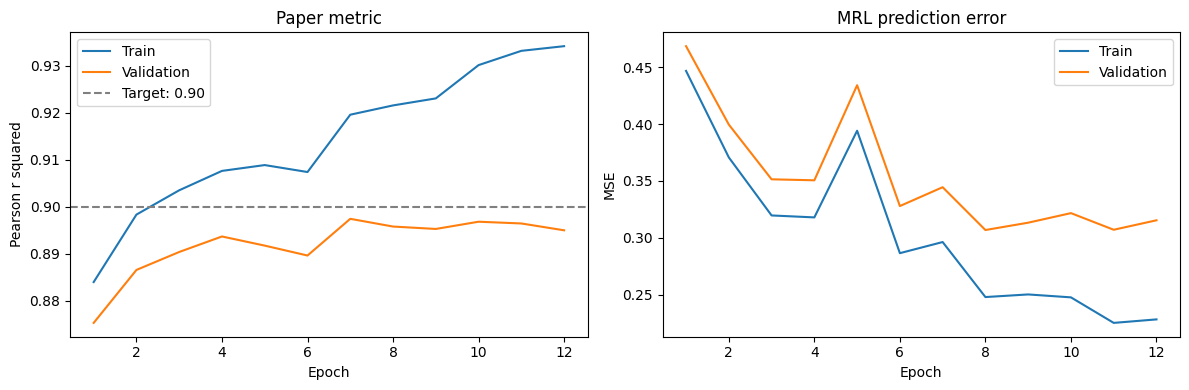

In [7]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].axhline(0.90, color="gray", linestyle="--", label="Target: 0.90")
for ax, metric, label in zip(axes, ["r2", "mse"], ["Pearson r squared", "MSE"]):
    ax.plot(history_df["epoch"], history_df[f"train_{metric}"], label="Train")
    ax.plot(history_df["epoch"], history_df[f"val_{metric}"], label="Validation")
    ax.set(xlabel="Epoch", ylabel=label)
    ax.legend()

fig.tight_layout()
fig.savefig(OUTCOMES_DIR / "training_curves.png", dpi=200)
plt.show()


## Evaluation

Load the best checkpoint and evaluate each group. The 0.90 target applies to the high-read test set; report low-read performance separately.


In [8]:
checkpoint = torch.load(OUTCOMES_DIR / "best_model.pth", map_location=device)
model.load_state_dict(checkpoint["model_state"])
mrl_mean, mrl_std = checkpoint["mrl_mean"], checkpoint["mrl_std"]
low_read_loader = DataLoader(make_dataset(low_read_data), batch_size=batch_size)

scores, predictions = {}, {}
for name, loader in [("validation", validating_loader), ("test_high_reads", testing_loader),
                     ("low_reads", low_read_loader)]:
    actual, predicted = predict(model, loader)
    mse, r, r2 = calculate_metrics(actual, predicted)
    scores[name] = {"dataset": name, "n": len(actual), "mse": mse,
                    "rmse": np.sqrt(mse), "pearson_r": r, "paper_r2": r2}
    predictions[name] = actual, predicted

metrics = pd.DataFrame(list(scores.values()))
metrics.to_csv(OUTCOMES_DIR / "metrics.csv", index=False)
actual_test, predicted_test = predictions["test_high_reads"]
test_mse = scores["test_high_reads"]["mse"]
test_r2 = scores["test_high_reads"]["paper_r2"]

test_predictions = pd.DataFrame({
    "utr": testing["utr"].to_numpy(),
    "total_reads": testing["total_reads"].to_numpy(),
    "actual_mrl": actual_test, "predicted_mrl": predicted_test,
})
test_predictions.to_csv(OUTCOMES_DIR / "test_predictions.csv", index=False)
print("Best epoch:", checkpoint["epoch"])
print(metrics.round(4).to_string(index=False))


C:\Users\ROG\AppData\Local\Temp\ipykernel_2888\4280899466.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(OUTCOMES_DIR / "best_model.pth", map_lo

Best epoch: 7
        dataset     n    mse   rmse  pearson_r  paper_r2
     validation 20000 0.3445 0.5870     0.9473    0.8974
test_high_reads 20000 0.3348 0.5786     0.9749    0.9504
      low_reads 46033 4.0724 2.0180     0.5691    0.3238


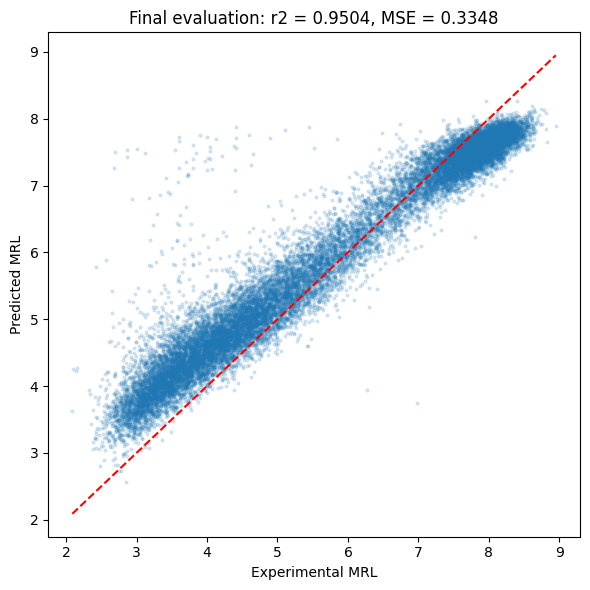

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(actual_test, predicted_test, s=4, alpha=0.15)
minimum = min(actual_test.min(), predicted_test.min())
maximum = max(actual_test.max(), predicted_test.max())
ax.plot([minimum, maximum], [minimum, maximum], "r--")
ax.set(xlabel="Experimental MRL", ylabel="Predicted MRL",
       title=f"Final evaluation: r2 = {test_r2:.4f}, MSE = {test_mse:.4f}")
fig.tight_layout()
fig.savefig(OUTCOMES_DIR / "mrl_predictions.png", dpi=200)
plt.show()


## New sequences

After training, pass a list of 50 nt `ATGC` sequences to `predict_mrl`. Predictions are in original MRL units.


In [10]:
def predict_mrl(sequences):
    encoded = np.stack([one_hot_encode(utr) for utr in sequences])
    model.eval()
    with torch.inference_mode():
        predictions, _ = model(torch.from_numpy(encoded).to(device))
    predictions = predictions.cpu().numpy() * mrl_std + mrl_mean
    return pd.DataFrame({"utr": sequences, "predicted_mrl": predictions})


Results are saved in `outcomes_multiscale`: `best_model.pth`, `training_history.csv`, `metrics.csv`, `test_predictions.csv` and plots.

Sources: [paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC7100133/) · [original code](https://github.com/pjsample/human_5utr_modeling).

The multiscale residual blocks and auxiliary loss are modifications to the original model.
